In [9]:
# Imports and Paths

import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent
data_dir = project_root / "data"
raw_dir = data_dir / "raw"
processed_dir = data_dir / "processed"
figures_dir = project_root / "figures"

processed_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

In [10]:
# Setup and load data

sns.set(style="whitegrid")

data_path = data_dir / "processed" / "cisplatin_rnaseq_modelready.csv"

df = pd.read_csv(data_path)
df.shape, df.head()

((743, 41146),
     model_id  drug_name   ln_ic50     A1BG  A1BG-AS1    A1CF      A2M  \
 0  SIDM01132  Cisplatin  3.168266  5.18545    2.9833  0.0000  0.52325   
 1  SIDM00848  Cisplatin -0.007561  4.86890    3.4476  0.0000  1.99640   
 2  SIDM00269  Cisplatin  0.045420  4.54970    3.8001  0.0841  3.21570   
 3  SIDM00203  Cisplatin  0.923136  4.22500    3.2095  0.0144  0.50590   
 4  SIDM01111  Cisplatin -0.134330  4.49250    2.8115  0.0144  0.47510   
 
    A2M-AS1   A2ML1  A2ML1-AS1  ...     ZXDA     ZXDB     ZXDC  ZYG11A  \
 0   0.0000  0.0213        0.0  ...  0.31285  1.60475  3.10825  0.6801   
 1   0.1243  3.1890        0.0  ...  1.68260  2.33060  5.18630  0.0841   
 2   0.0566  0.5753        0.0  ...  2.82980  3.41280  6.78270  2.3190   
 3   0.0976  2.8156        0.0  ...  2.49570  3.47640  5.30710  3.0321   
 4   0.0286  0.5558        0.0  ...  1.28690  2.26000  4.94810  2.7634   
 
    ZYG11AP1   ZYG11B      ZYX  ZYXP1    ZZEF1    ZZZ3  
 0       0.0  2.58955  5.95435    0.

In [11]:
# Define key columns

model_col = "model_id"
drug_col = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col] # columns that aren't genes
feature_cols = [c for c in df.columns if c not in non_feature_cols]

len(feature_cols)

41143

    model_id  drug_name   ln_ic50
0  SIDM01132  Cisplatin  3.168266
1  SIDM00848  Cisplatin -0.007561
2  SIDM00269  Cisplatin  0.045420
3  SIDM00203  Cisplatin  0.923136
4  SIDM01111  Cisplatin -0.134330
count    743.000000
mean       3.193923
std        1.844741
min       -1.730244
25%        1.808377
50%        3.070274
75%        4.429676
max        9.229988
Name: ln_ic50, dtype: float64


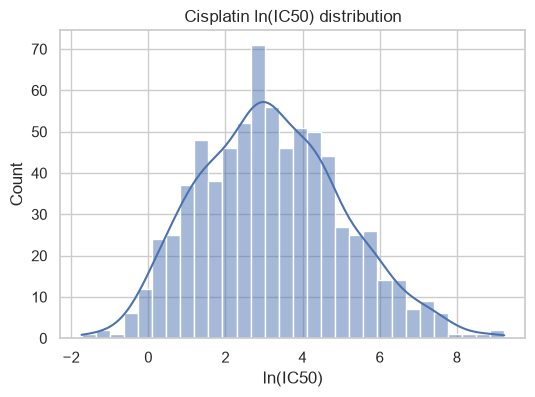

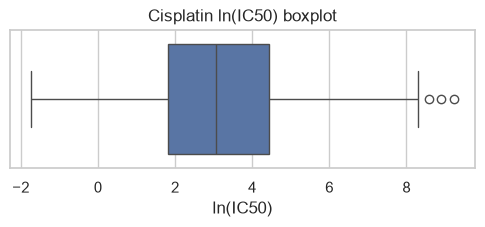

In [12]:
# Basic checks and summary of LN_IC50

print(df[[model_col, drug_col, response_col]].head())
print(df[response_col].describe())

plt.figure(figsize=(6,4))
sns.histplot(df[response_col], bins=30, kde=True)
plt.xlabel("ln(IC50)")
plt.title("Cisplatin ln(IC50) distribution")
plt.show()

plt.figure(figsize=(6,1.8))
sns.boxplot(x=df[response_col])
plt.xlabel("ln(IC50)")
plt.title("Cisplatin ln(IC50) boxplot")
plt.show()

In [13]:
# Missingness

missing_frac = df[feature_cols].isna().mean()
print("Max missing fraction:", missing_frac.max())

# How many genes have >50% missing?
(missing_frac > 0.5).sum()

Max missing fraction: 0.6069986541049798


np.int64(4705)

In [14]:
# Basic variance:

feature_var = df[feature_cols].var()

# 10 highest variances
print(feature_var.sort_values(ascending=False).head(10))

# 10 lowest variances
feature_var.sort_values().head(10)

KRT19       18.170758
SPARC       16.088315
VIM         15.472241
KRT7        14.890913
KRT8        14.819599
C19orf33    14.793465
UCHL1       14.638180
TGFBI       14.237309
RPS4Y1      13.996133
KRT18       13.418657
dtype: float64


MT-TL1         0.0
MT-TH          0.0
MT-TG          0.0
MT-TF          0.0
MT-TE          0.0
MT-TD          0.0
MT-TC          0.0
MT-TA          0.0
RNU4ATAC3P     0.0
RNU4ATAC15P    0.0
dtype: float64

In [15]:
# Quick univariate correlation screen
# **Not a true top list, correlations only computed for random 1000 genes

np.random.seed(42)
sampled_genes = np.random.choice(feature_cols, size=1000, replace=False)

corrs = df[list(sampled_genes) + [response_col]].corr()[response_col].drop(response_col)
top_pos = corrs.sort_values(ascending=False).head(10)
top_neg = corrs.sort_values().head(10)

top_pos, top_neg

(WWC1        0.444481
 CTTN        0.414323
 KRT18P11    0.369071
 ELOVL1      0.363345
 SEC14L2     0.355411
 DKK1        0.343567
 PRRG2       0.342314
 ELOVL7      0.323690
 KIF3B       0.309777
 FOSL2       0.306935
 Name: ln_ic50, dtype: float64,
 IRAG2    -0.411404
 RPS28    -0.383305
 BTK      -0.376653
 NLRC3    -0.371475
 RPL18A   -0.365344
 TRGV4    -0.339829
 CD69     -0.337339
 ZGRF1    -0.336846
 MRPS31   -0.334288
 ZNF101   -0.334236
 Name: ln_ic50, dtype: float64)

In [16]:
# Save a lightly cleaned version

keep_genes = missing_frac[missing_frac <= 0.3].index.tolist() # keep genes with at most 30% missing
df_clean = df[non_feature_cols + keep_genes].copy()

clean_path = data_dir / "processed" / "cisplatin_rnaseq_modelready_clean.csv"
df_clean.to_csv(clean_path, index=False)
clean_path, df_clean.shape

(WindowsPath('C:/Users/draar/gdsc-drug-response-project/data/processed/cisplatin_rnaseq_modelready_clean.csv'),
 (743, 36441))